# Assignment 4: parts 4 and 5 (V1 vs LM)
Session 715093703, loaded with the partner's `ecephys_setup.py` (keep it in the same folder as this notebook).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import procrustes
from ecephys_setup import get_session, get_units, get_spikes, clean_grating_spike_data

SESSION_ID = 715093703
REGIONS = {"VISp": "V1", "VISl": "LM"}
N_PCS = 5
COLLAPSE_TO_ORIENTATION = False   # True: merge opposite directions into 4 orientations

/Users/erkhesmunkhchuluun/miniforge3/envs/allensdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load spike counts (one row per grating trial, one column per unit)

In [2]:
session = get_session(SESSION_ID)
counts = {}
for area in REGIONS:
    stims, units = get_units(session, region=area)
    clean = clean_grating_spike_data(get_spikes(session, stims, units), stims)
    trials = stims[stims["orientation"].notna() & (stims["orientation"] != "null")]
    counts[area] = (clean.groupby(["stimulus_presentation_id", "unit_id"]).size()
                         .unstack(fill_value=0)
                         .reindex(index=trials.index, columns=units.index, fill_value=0).values)

direction = trials["orientation"].astype(float).values
labels = direction % 180 if COLLAPSE_TO_ORIENTATION else direction
classes = np.unique(labels)
period = 180 if COLLAPSE_TO_ORIENTATION else 360
color_of = lambda v: plt.get_cmap("hsv")(v / period)

/Users/erkhesmunkhchuluun/miniforge3/envs/allensdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


## PCA

In [3]:
def zscore(X):
    sd = X.std(axis=0); sd[sd == 0] = 1.0
    return (X - X.mean(axis=0)) / sd

def pca(X):
    Xc = X - X.mean(axis=0)
    eigvals, eigvecs = np.linalg.eigh(Xc.T @ Xc / len(Xc))
    order = np.argsort(eigvals)[::-1]
    eigvals = np.clip(eigvals[order], 0, None)
    return Xc @ eigvecs[:, order], eigvals / eigvals.sum()

res = {}
for area in REGIONS:
    Z = zscore(counts[area].astype(float))
    avg = np.array([Z[labels == c].mean(axis=0) for c in classes])
    res[area] = {"trial": pca(Z), "avg": pca(avg)}

## Part 4a: PCA, trial-by-trial

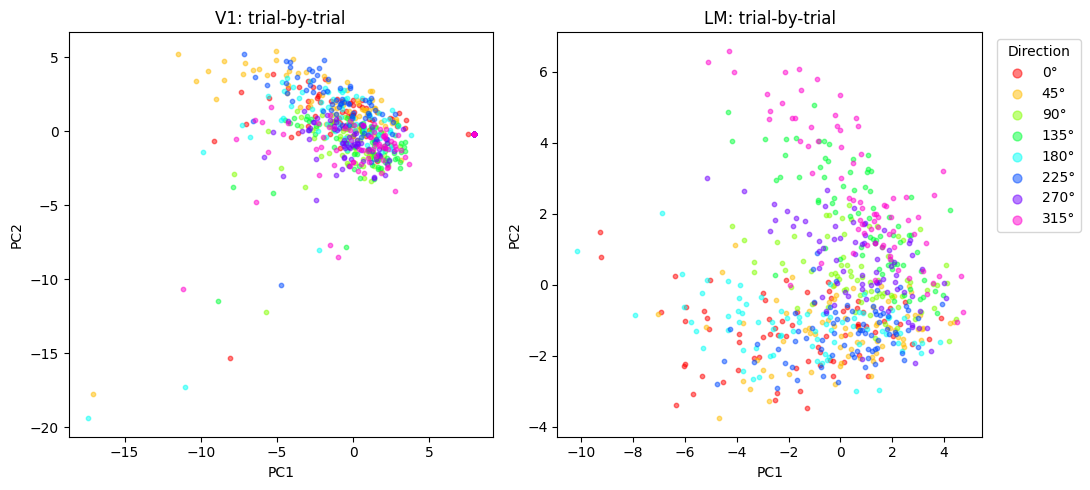

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (area, name) in zip(axes, REGIONS.items()):
    s, v = res[area]["trial"]
    for c in classes:
        m = labels == c
        ax.scatter(s[m, 0], s[m, 1], s=10, alpha=0.5, color=color_of(c), label=f"{c:g}°")
    ax.set(title=f"{name}: trial-by-trial", xlabel="PC1", ylabel="PC2")
axes[1].legend(title="Direction", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=2)
fig.tight_layout(); plt.show()

## Part 4b: PCA, orientation-averaged

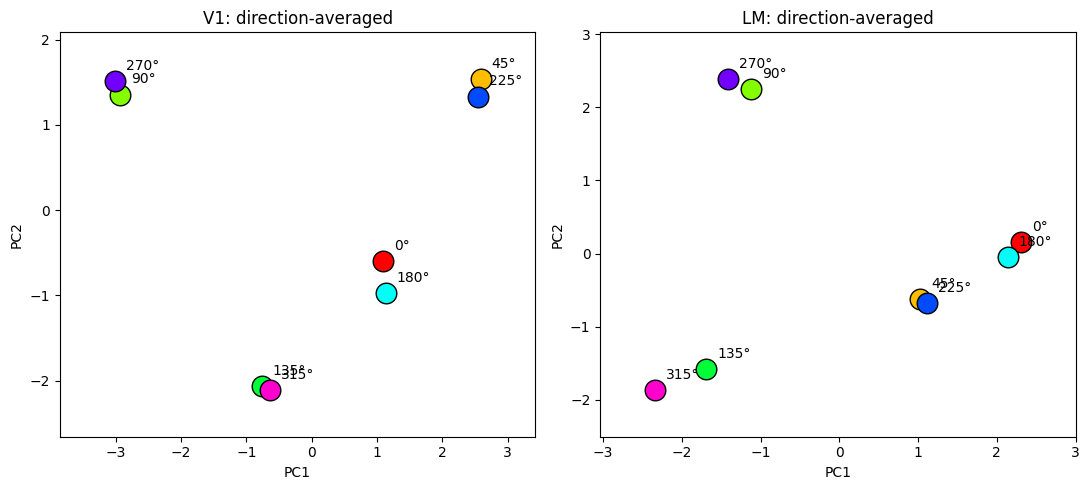

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (area, name) in zip(axes, REGIONS.items()):
    s, v = res[area]["avg"]
    for i, c in enumerate(classes):
        ax.scatter(s[i, 0], s[i, 1], s=220, color=color_of(c), edgecolor="k")
        ax.annotate(f"{c:g}°", (s[i, 0], s[i, 1]), xytext=(8, 8), textcoords="offset points")
        ax.set(title=f"{name}: direction-averaged", xlabel="PC1", ylabel="PC2")
    ax.margins(0.15)
fig.tight_layout(); plt.show()

## Part 5: Procrustes on the top 5 PCs

In [13]:
V1_avg, LM_avg, _ = procrustes(res["VISp"]["avg"][0][:, :N_PCS], res["VISl"]["avg"][0][:, :N_PCS])
V1_tr, LM_tr, _ = procrustes(res["VISp"]["trial"][0][:, :N_PCS], res["VISl"]["trial"][0][:, :N_PCS])

### Part 5a: alignment, orientation-averaged (filled = V1, hollow = aligned LM)

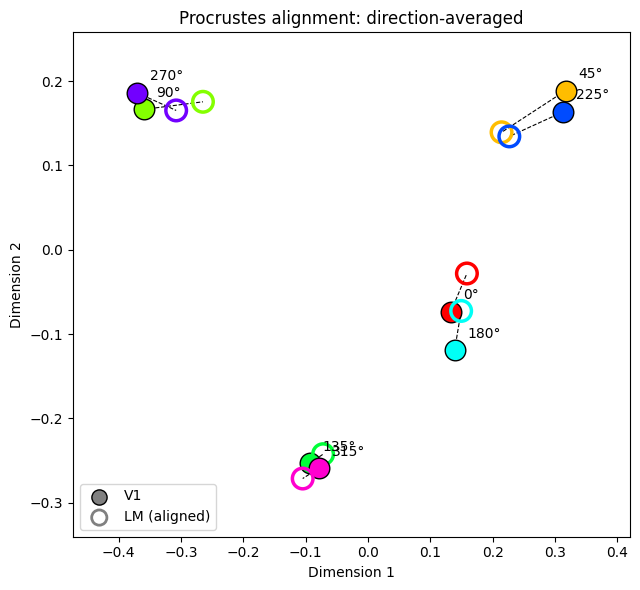

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for i, c in enumerate(classes):
    ax.plot([V1_avg[i, 0], LM_avg[i, 0]], [V1_avg[i, 1], LM_avg[i, 1]], "k--", lw=0.8)
    ax.scatter(*V1_avg[i, :2], s=220, color=color_of(c), edgecolor="k", zorder=3)
    ax.scatter(*LM_avg[i, :2], s=220, facecolor="none", edgecolor=color_of(c), lw=2.5, zorder=3)
    ax.annotate(f"{c:g}°", V1_avg[i, :2], xytext=(9, 9), textcoords="offset points")
ax.scatter([], [], s=120, color="gray", edgecolor="k", label="V1")
ax.scatter([], [], s=120, facecolor="none", edgecolor="gray", lw=2, label="LM (aligned)")
ax.legend()
ax.set(title="Procrustes alignment: direction-averaged", xlabel="Dimension 1", ylabel="Dimension 2")
ax.margins(0.15)
fig.tight_layout(); plt.show()

### Part 5b: alignment, trial-by-trial

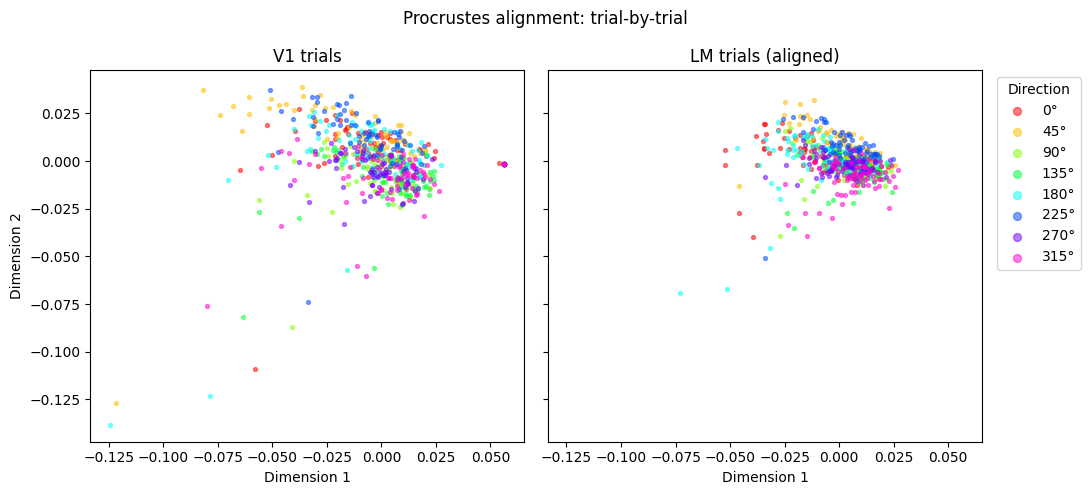

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, pts, title in [(axes[0], V1_tr, "V1 trials"), (axes[1], LM_tr, "LM trials (aligned)")]:
    for c in classes:
        m = labels == c
        ax.scatter(pts[m, 0], pts[m, 1], s=8, alpha=0.5, color=color_of(c), label=f"{c:g}°")
    ax.set(title=title, xlabel="Dimension 1")
axes[0].set_ylabel("Dimension 2")
axes[1].legend(title="Direction", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=2)
fig.suptitle("Procrustes alignment: trial-by-trial")
fig.tight_layout(); plt.show()